In [ ]:
df.columns

Index(['Date', 'Close', 'Volume', 'Open', 'High', 'Low', 'Unnamed: 6',
       'Date.1', 'High.1'],
      dtype='object')

In [ ]:
!pip install tensorflow
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

In [ ]:
df1 = df[["Open"]].values
df1

NameError: name 'df' is not defined

In [ ]:
df1 = df["Open"].replace({r'\$': '', ',' : ''}, regex=True).astype(float)
df1

0      185.52
1      191.57
2      195.04
3      196.24
4      196.06
        ...  
120    149.46
121    153.78
122    153.88
123    150.64
124    152.58
Name: Open, Length: 125, dtype: float64

In [ ]:
print(df1.shape)

(125,)


In [ ]:
num_of_prices = len(df1)
print(len(df1))

125


In [ ]:
apple_price_features = []
apple_price_labels = []
for i in range(10, (num_of_prices)):
    apple_price_features.append(df1[i-10:i])
    apple_price_labels.append(df1[i])

In [ ]:
x_train = np.array(apple_price_features[0:100])
y_train = np.array(apple_price_labels[0:100])

In [ ]:
print(x_train.shape)
print(y_train.shape)

(100, 10)
(100,)


In [ ]:
x_test = np.array(apple_price_features[101:])
y_test = np.array(apple_price_labels[101:])

In [ ]:
df = pd.read_csv("all_apple_stock_data.csv")
df.head(50)

,Date,Close,Volume,Open,High,Low,Unnamed: 6,Date.1,High.1
0,8/4/2023,$181.99,115956800,$185.52,$187.38,$181.92,NaN,8/4/2023,187.3800
1,8/3/2023,$191.17,62243280,$191.57,$192.37,$190.69,NaN,8/3/2023,192.3700
2,8/2/2023,$192.58,50389330,$195.04,$195.18,$191.85,NaN,8/2/2023,195.1800
3,8/1/2023,$195.61,35281430,$196.24,$196.73,$195.28,NaN,8/1/2023,196.7300
4,7/31/2023,$196.45,38824110,$196.06,$196.49,$195.26,NaN,7/31/2023,196.4900
5,7/28/2023,$195.83,48291440,$194.67,$196.63,$194.14,NaN,7/28/2023,196.6260
6,7/27/2023,$193.22,47460180,$196.02,$197.20,$192.55,NaN,7/27/2023,197.2000
7,7/26/2023,$194.50,47471870,$193.67,$195.64,$193.32,NaN,7/26/2023,195.6400
8,7/25/2023,$193.62,37283200,$193.33,$194.44,$192.92,NaN,7/25/2023,194.4400
9,7/24/2023,$192.75,45505100,$193.41,$194.91,$192.25,NaN,7/24/2023,194.9100


In [ ]:
x_test = np.array(apple_price_features[101:])
y_test = np.array(apple_price_labels[101:])
x_test = np.reshape(x_test, (x_test.shape[0], x_test.shape[1], 1))
print(x_test.shape)

(14, 10, 1)


In [ ]:
from tensorflow.keras.layers import Input, Dense, Dropout, LSTM
from tensorflow.keras.models import Model

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import Input, LSTM, Dropout, Dense
from tensorflow.keras.models import Model

if x_train.ndim == 2:
    x_train = x_train[..., np.newaxis]
if 'x_test' in globals() and x_test.ndim == 2:
    x_test = x_test [..., np.newaxis]

inp = Input(shape=(x_train.shape[1], x_train.shape[2]))
lstm1 = LSTM(100, activation = 'tanh', return_sequences=True, name= 'lstm1')(inp)
drop1 = Dropout(0.1)(lstm1)
lstm2 = LSTM(120, activation = 'tanh', return_sequences=True, name ='lstm2')(drop1)
lstm3 = LSTM(80, activation = 'tanh', return_sequences=True, name ='lstm3')(lstm2)
lstm4 = LSTM(50, activation = 'tanh', return_sequences=False, name ='lstm4')(lstm3)
out = Dense(1, name='output')(lstm4)
model = Model(inp, out)
model.compile(optimizer="adam", loss="mse")
model.summary()
print("x_train shape: ", x_train.shape)
print("y_train shape: ", y_train.shape)

#LSTM (LOng Short Tem Memoryu)
#Definition: A tupe of Recurrent Neural Network (RNN) used fo rsequential data (like time series, language, etx.)
#Why its special" it has a memory cell that helps it remembvers information for long periods, avoiding issues like vnishing fradients (information that we provide to our data)
#Common uses" Languiages trasnlation, speech recognition, stock price prediction, etc.
#
#Dropout Layer: A technique to prevent overfitting by randomly turning off some neurons during training
#It forces the network to not depend too much on specific neurons
#Is thto prevent the networks using redundant or unnecessary info
#It is also to prevent overfitting the neurons with data

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)           │ (None, 10, 1)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm1 (LSTM)                         │ (None, 10, 100)             │          40,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_7 (Dropout)                  │ (None, 10, 100)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm2 (LSTM)                         │ (None, 10, 120)             │         106,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm3 (LSTM)                         │ (None, 10, 80)              │          64,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm4 (LSTM)                         │ (None, 50)                  │          26,200 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ output (Dense)                       │ (None, 1)                   │              51 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 237,451 (927.54 KB)

 Trainable params: 237,451 (927.54 KB)

 Non-trainable params: 0 (0.00 B)

x_train shape:  (100, 10, 1)
y_train shape:  (100,)


In [ ]:
x_test = np.array([[[float(str(sub_price).replace('$', '').replace(',', '')) for sub_price in inner_list] for inner_list in outer_list] for outer_list in x_test])

y_test = x_test.astype(np.float32)
x_test = x_test.astype(np.float32)

x_test = np.reshape(x_test, (x_test.shape[0], x_test.shape[1], 1))

In [ ]:
y_pred = model.predict(x_test)

print(y_pred.shape)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 485ms/step
(14, 1)


In [ ]:
scaler = MinMaxScaler()
df1 = df['Open'].replace({'\$': '', ',': ''}, regex=True.astype(float))
df1 = df1.values.reshape(-1,1)
df1 = scaler.fit_transform(df1)

AttributeError: 'bool' object has no attribute 'astype'

In [ ]:
print(y_test.shape)

(14, 10, 1)


In [ ]:
y_test = y_test.reshape(-1,1)
y_test = scaler.inverse_transform(y_test)
print(y_test)

NotFittedError: This MinMaxScaler instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.

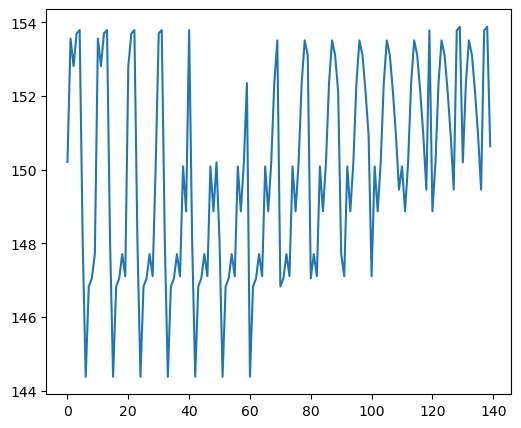

In [ ]:
plt.figure(figsize = (6,5))
plt.plot(y_test, )